In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import fft

## Aufgabenstellung

Skizziere von den folgenden Funktionen das Amplitudenspektrum (mit `scipy.fft` bzw. `numpy.fft`):

Funktion 1: Quadrat

$$f(x,y) = \begin{cases} 
1 & |x| \leq 1 \land |y| \leq 1 \\
0 & |x| > 1 \lor |y| > 1
\end{cases}$$

Funktion 2: Kreis

$$f(x,y) = \begin{cases} 
1 & \sqrt{x^2 + y^2} \leq 1 \\
0 & \sqrt{x^2 + y^2} > 1
\end{cases}$$

Funktion 3: 2D-Gauss

$$f(x,y) = \frac{1}{2\pi} e^{-\frac{\sqrt{x^2 + y^2}}{2}}$$

---

**Bedingungen:**
- Bereich: $-2 \leq x \leq 2$ und $-2 \leq y \leq 2$
- Datenpunkte: $64 \times 64$

## Gitter erstellt

Wir haben ein $64 \times 64$ Gitter im Bereich $[-2, 2] \times [-2, 2]$ erstellt.

Jetzt definieren wir die drei Funktionen.

In [2]:
n = 64
x = np.linspace(-2, 2, n)
y = np.linspace(-2, 2, n)
X, Y = np.meshgrid(x, y)

In [3]:
# definieren der ersten Funktion
f1 = np.zeros((n,n))
mask1 = (np.abs(X) <= 1) & (np.abs(Y) <= 1)
f1[mask1] = 1
print(f"Anzahl Punkte mit f=1: {np.sum(f1 == 1)}")
print(f"Anzahl Punkte mit f=0: {np.sum(f1 == 0)}")

Anzahl Punkte mit f=1: 1024
Anzahl Punkte mit f=0: 3072


In [4]:
# definieren der zweiten Funktion
f2 = np.zeros((n,n))
R = np.sqrt(X**2 + Y**2)
mask2 = R <= 1
f2[mask2] = 1
print(f"Anzahl Punkte mit f=1: {np.sum(f2 == 1)}")
print(f"Anzahl Punkte mit f=0: {np.sum(f2 == 0)}")

Anzahl Punkte mit f=1: 788
Anzahl Punkte mit f=0: 3308


In [5]:
# definieren der dritten Funktion
f3 = (1/ (2*np.pi)) * np.exp(-R / 2)
print(f"Minimum: {f3.min():.6f}")
print(f"Maximum: {f3.max():.6f}")
print(f"Wert bei (0,0): {f3[n//2, n//2]:.6f}")

Minimum: 0.038693
Maximum: 0.155622
Wert bei (0,0): 0.155622


## Funktionen definiert

Alle drei Funktionen wurden erfolgreich definiert:
- **f1 (Quadrat)**: Sprungfunktion mit scharfen Kanten
- **f2 (Kreis)**: Kreisförmige Maske mit Sprung am Rand  
- **f3 (2D-Gauss)**: Glatte, kontinuierliche Funktion

Als nächstes berechnen wir die 2D-Fouriertransformation.

## 2D-Fouriertransformation

Die 2D-FFT wird mit `scipy.fft.fft2()` berechnet. Anschliessend verwenden wir `fft.fftshift()`, um die DC-Komponente (Frequenz 0) in die Mitte zu verschieben - das erleichtert die Visualisierung.

**Amplitudenspektrum:**
$$A(u,v) = |F(u,v)|$$

**Log-Amplitudenspektrum** (für bessere Sichtbarkeit):
$$A_{log}(u,v) = \log_{10}(|F(u,v)| + 1)$$

In [6]:
# FFT für alle drei Funktionen
F1 = fft.fft2(f1)
F2 = fft.fft2(f2)
F3 = fft.fft2(f3)

# Shift: DC-Komponente in die Mitte
F1_shifted = fft.fftshift(F1)
F2_shifted = fft.fftshift(F2)
F3_shifted = fft.fftshift(F3)

# Amplitudenspektren (Betrag)
A1 = np.abs(F1_shifted)
A2 = np.abs(F2_shifted)
A3 = np.abs(F3_shifted)

# Log-Skalierung für bessere Visualisierung
A1_log = np.log10(A1 + 1)  # +1 um log(0) zu vermeiden
A2_log = np.log10(A2 + 1)
A3_log = np.log10(A3 + 1)

print("\n2D-FFT berechnet für alle drei Funktionen")


2D-FFT berechnet für alle drei Funktionen


## Visualisierung

Wir zeigen für jede Funktion drei Darstellungen:
1. **Originalfunktion** im Ortsraum
2. **Amplitudenspektrum** im Frequenzraum
3. **Log-Amplitudenspektrum** (bessere Sichtbarkeit kleiner Werte)

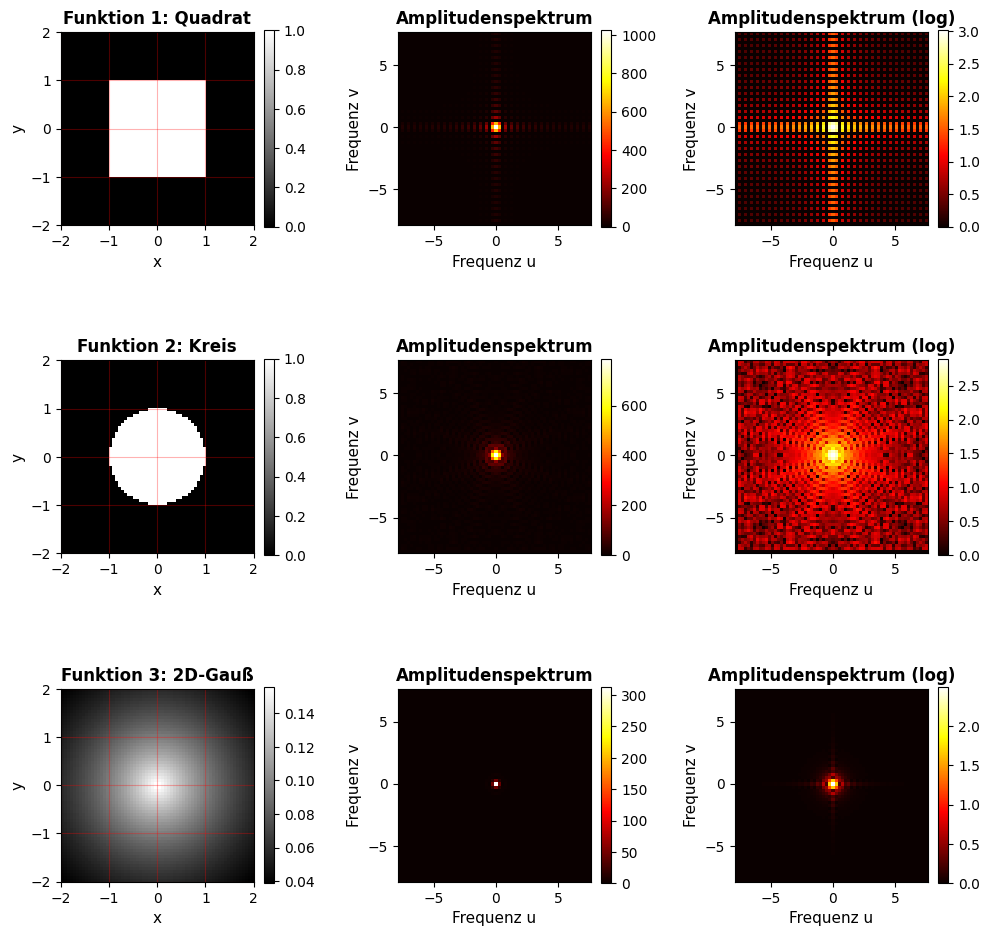

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(10, 10))

# Frequenz-Achsen für Spektren
freq = fft.fftshift(fft.fftfreq(n, d=(x[1]-x[0])))
extent_space = [x.min(), x.max(), y.min(), y.max()]
extent_freq = [freq.min(), freq.max(), freq.min(), freq.max()]

# ----- FUNKTION 1: QUADRAT -----
# Original
im1 = axes[0, 0].imshow(f1, extent=extent_space, origin='lower', cmap='gray')
axes[0, 0].set_xlabel('x', fontsize=11)
axes[0, 0].set_ylabel('y', fontsize=11)
axes[0, 0].set_title('Funktion 1: Quadrat', fontsize=12, fontweight='bold')
axes[0, 0].grid(True, alpha=0.3, color='red')
plt.colorbar(im1, ax=axes[0, 0], fraction=0.046)

# Amplitudenspektrum
im2 = axes[0, 1].imshow(A1, extent=extent_freq, origin='lower', cmap='hot')
axes[0, 1].set_xlabel('Frequenz u', fontsize=11)
axes[0, 1].set_ylabel('Frequenz v', fontsize=11)
axes[0, 1].set_title('Amplitudenspektrum', fontsize=12, fontweight='bold')
plt.colorbar(im2, ax=axes[0, 1], fraction=0.046)

# Log-Amplitudenspektrum
im3 = axes[0, 2].imshow(A1_log, extent=extent_freq, origin='lower', cmap='hot')
axes[0, 2].set_xlabel('Frequenz u', fontsize=11)
axes[0, 2].set_ylabel('Frequenz v', fontsize=11)
axes[0, 2].set_title('Amplitudenspektrum (log)', fontsize=12, fontweight='bold')
plt.colorbar(im3, ax=axes[0, 2], fraction=0.046)


# ----- FUNKTION 2: KREIS -----
# Original
im4 = axes[1, 0].imshow(f2, extent=extent_space, origin='lower', cmap='gray')
axes[1, 0].set_xlabel('x', fontsize=11)
axes[1, 0].set_ylabel('y', fontsize=11)
axes[1, 0].set_title('Funktion 2: Kreis', fontsize=12, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, color='red')
plt.colorbar(im4, ax=axes[1, 0], fraction=0.046)

# Amplitudenspektrum
im5 = axes[1, 1].imshow(A2, extent=extent_freq, origin='lower', cmap='hot')
axes[1, 1].set_xlabel('Frequenz u', fontsize=11)
axes[1, 1].set_ylabel('Frequenz v', fontsize=11)
axes[1, 1].set_title('Amplitudenspektrum', fontsize=12, fontweight='bold')
plt.colorbar(im5, ax=axes[1, 1], fraction=0.046)

# Log-Amplitudenspektrum
im6 = axes[1, 2].imshow(A2_log, extent=extent_freq, origin='lower', cmap='hot')
axes[1, 2].set_xlabel('Frequenz u', fontsize=11)
axes[1, 2].set_ylabel('Frequenz v', fontsize=11)
axes[1, 2].set_title('Amplitudenspektrum (log)', fontsize=12, fontweight='bold')
plt.colorbar(im6, ax=axes[1, 2], fraction=0.046)


# ----- FUNKTION 3: 2D-GAUSS -----
# Original
im7 = axes[2, 0].imshow(f3, extent=extent_space, origin='lower', cmap='gray')
axes[2, 0].set_xlabel('x', fontsize=11)
axes[2, 0].set_ylabel('y', fontsize=11)
axes[2, 0].set_title('Funktion 3: 2D-Gauß', fontsize=12, fontweight='bold')
axes[2, 0].grid(True, alpha=0.3, color='red')
plt.colorbar(im7, ax=axes[2, 0], fraction=0.046)

# Amplitudenspektrum
im8 = axes[2, 1].imshow(A3, extent=extent_freq, origin='lower', cmap='hot')
axes[2, 1].set_xlabel('Frequenz u', fontsize=11)
axes[2, 1].set_ylabel('Frequenz v', fontsize=11)
axes[2, 1].set_title('Amplitudenspektrum', fontsize=12, fontweight='bold')
plt.colorbar(im8, ax=axes[2, 1], fraction=0.046)

# Log-Amplitudenspektrum
im9 = axes[2, 2].imshow(A3_log, extent=extent_freq, origin='lower', cmap='hot')
axes[2, 2].set_xlabel('Frequenz u', fontsize=11)
axes[2, 2].set_ylabel('Frequenz v', fontsize=11)
axes[2, 2].set_title('Amplitudenspektrum (log)', fontsize=12, fontweight='bold')
plt.colorbar(im9, ax=axes[2, 2], fraction=0.046)

plt.tight_layout()
plt.show()

## Beobachtungen und Interpretation

### 1. Quadrat

- **Scharfe Kanten** → viele hohe Frequenzen
- **Sinc-Funktion** Muster im Frequenzraum
- **Kreuzförmige Struktur** durch rechteckige Form
- Die horizontalen und vertikalen Kanten erzeugen entsprechende Strukturen im Spektrum

**Mathematisch:** $\mathcal{F}\{\text{rect}(x,y)\} = \text{sinc}(u) \cdot \text{sinc}(v)$

---

### 2. Kreis

- **Runde Form** → rotationssymmetrisches Spektrum
- **Airy-Disk** Muster (Bessel-Funktion)
- **Konzentrische Ringe** im Frequenzraum
- Die Rotationssymmetrie der Funktion bleibt im Frequenzraum erhalten

**Mathematisch:** $\mathcal{F}\{\text{circ}(r)\} \propto \frac{J_1(2\pi r\rho)}{\rho}$ (Bessel-Funktion erster Art)

---

### 3. 2D-Gauss

- **Glatte Funktion** → Spektrum konzentriert bei niedrigen Frequenzen
- **Gauss bleibt Gauss** unter Fouriertransformation (besondere Eigenschaft!)
- Sehr wenig hohe Frequenzen (keine scharfen Kanten)
- Das Spektrum ist ebenfalls gaussförmig und rotationssymmetrisch

**Mathematisch:** $\mathcal{F}\{e^{-\pi r^2}\} = e^{-\pi \rho^2}$

---

## Physikalische Interpretation

**Zusammenhang zwischen Glätte und Frequenzgehalt:**

Je **glatter** eine Funktion ist, desto mehr Energie liegt bei **niedrigen Frequenzen**.  
Je mehr **Kanten/Diskontinuitäten**, desto mehr **hohe Frequenzen** werden benötigt.

| Funktion | Glätte | Hohe Frequenzen | Spektrum-Charakteristik |
|----------|--------|-----------------|-------------------------|
| 2D-Gauss | Sehr glatt | Sehr wenig | Konzentriert in der Mitte |
| Kreis    | Sprung am Rand | Mittel | Airy-Disk mit Ringen |
| Quadrat  | Scharfe Ecken | Viel | Sinc-Muster, Kreuzform |

---

## Fazit

Die 2D-Fouriertransformation zeigt deutlich:
- **Diskontinuitäten** (wie beim Quadrat und Kreis) erfordern viele hohe Frequenzen
- **Glatte Funktionen** (wie der Gauss) haben Energie hauptsächlich bei niedrigen Frequenzen
- Die **Symmetrie** im Ortsraum bleibt im Frequenzraum erhalten